# 04 – Modelagem: o aluno será alfabetizado?

**Problema:** classificação binária. O modelo estima a probabilidade de um aluno do 2º ano ser
alfabetizado (proficiência ≥ 743) usando só informações disponíveis **antes** da prova.

**Cenário de uso:** no início de 2024, a secretaria conhece a rede do aluno, o município, o contexto
socioeconômico e os resultados de 2023. Com isso, o modelo indica **quais redes e municípios concentram
mais risco**, para orientar onde priorizar o reforço.

> **Importante:** as variáveis descrevem o município e a rede, não o aluno. Por isso, alunos da mesma rede
> no mesmo município recebem a mesma probabilidade. O modelo prioriza **redes e municípios**, não alunos
> individualmente.

**Roteiro**
1. Separação treino/teste por município
2. Comparação de algoritmos
3. Teste de vazamento de dados (*leakage*)
4. Contribuição de cada grupo de variáveis
5. Otimização de hiperparâmetros
6. Avaliação final no teste
7. Replicabilidade

In [1]:
# Configura o caminho do projeto para importar os módulos de src/.
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", None)
import warnings
warnings.filterwarnings("ignore", message=".*does not have valid feature names.*")
import numpy as np
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import roc_auc_score

from src.config import RANDOM_STATE, REPORTS_DIR
from src.modeling.pipeline import (ALVO, GRUPO, CATEGORICAS, NUMERICAS, TERRITORIO_CAT, TERRITORIO_NUM,
                                   SOCIOECONOMICAS, HISTORICO_EDUCACIONAL, METAS, ALUNO_CAT,
                                   criar_pipeline, modelos_candidatos, selecionar_X)
from src.modeling.train import (dividir_por_grupo, cv_por_grupo, avaliar_cv, otimizar, ESPACO_LGBM,
                                ESPACO_LOGISTICA, bootstrap_metrica, salvar_modelo, tabela_busca)
from src.evaluation.metrics import (resumo_cv, metricas, limiar_otimo_f1, grafico_avaliacao,
                                    grafico_matriz_confusao)
from src.visualization.style import aplicar_estilo, salvar, AZUL, LARANJA, CINZA, TEXTO_2
aplicar_estilo()

df = pd.read_parquet(ROOT / "data/processed/base_alunos_2024.parquet")
X, y, grupos = selecionar_X(df), df[ALVO], df[GRUPO]
print(f"Alunos: {len(df):,} | variáveis: {X.shape[1]} ({len(NUMERICAS)} numéricas + {len(CATEGORICAS)} categóricas)")

Alunos: 49,651 | variáveis: 51 (47 numéricas + 4 categóricas)


In [2]:
# Grupos de variáveis utilizados.
grupos_vars = {"Aluno": ALUNO_CAT, "Território": TERRITORIO_CAT + TERRITORIO_NUM,
               "Socioeconômicas (Atlas 2010)": SOCIOECONOMICAS,
               "Histórico educacional (2023)": HISTORICO_EDUCACIONAL, "Metas municipais": METAS}
pd.DataFrame([(g, len(v), ", ".join(v)) for g, v in grupos_vars.items()],
             columns=["grupo", "nº", "variáveis"]).set_index("grupo")

,nº,variáveis
grupo,,
Aluno,1,rede_ensino
Território,9,"sigla_uf, regiao, porte_municipio, capital, latitude, longitude, log_populacao, crescimento_pop_2010_2022, taxa_urbanizacao_2010"
Socioeconômicas (Atlas 2010),23,"idhm, idhm_educacao, idhm_longevidade, idhm_renda, renda_per_capita, gini, pct_extrema_pobreza, pct_pobres, pct_criancas_extrema_pobreza, taxa_analfabetismo_18mais, anos_estudo_esperados, taxa_freq_escola_4a5, taxa_freq_escola_5a6, taxa_atraso_2anos_fund, pct_criancas_lar_sem_fund_completo, pct_agua_encanada, pct_sem_agua_esgoto_adequado, pct_energia_eletrica, mortalidade_ate_5anos, esperanca_vida, razao_dependencia, grau_formalizacao_trabalho, taxa_desocupacao"
Histórico educacional (2023),11,"taxa_alfabetizacao_estadual_ant, taxa_alfabetizacao_municipal_ant, taxa_alfabetizacao_publica_ant, media_portugues_estadual_ant, media_portugues_municipal_ant, media_portugues_publica_ant, participacao_ant, nivel_alfabetizacao_ant, taxa_uf_publica_ant, taxa_rede_aluno_ant, media_rede_aluno_ant"
Metas municipais,7,"meta_alfabetizacao_2024, meta_alfabetizacao_2025, meta_alfabetizacao_2026, meta_alfabetizacao_2027, meta_alfabetizacao_2028, meta_alfabetizacao_2029, esforco_meta_2024"


## 1. Separação treino / teste

- **20% dos municípios ficam reservados para o teste final.** Todos os alunos de um município ficam no
  treino ou no teste, e o teste é usado uma única vez, no fim.
- **No treino, modelos e hiperparâmetros são escolhidos com validação cruzada por município**
  (`StratifiedGroupKFold`, 5 partes), mantendo a proporção de alfabetizados em cada parte.

In [3]:
idx_tr, idx_te = dividir_por_grupo(X, y, grupos, test_size=0.2)
X_tr, X_te, y_tr, y_te = X.iloc[idx_tr], X.iloc[idx_te], y.iloc[idx_tr], y.iloc[idx_te]
g_tr, g_te = grupos.iloc[idx_tr], grupos.iloc[idx_te]

assert set(g_tr).isdisjoint(set(g_te)), "Município presente no treino e no teste!"
pd.DataFrame({
    "alunos": [len(X_tr), len(X_te)],
    "municípios": [g_tr.nunique(), g_te.nunique()],
    "% alfabetizados": [y_tr.mean(), y_te.mean()],
}, index=["treino", "teste"]).style.format({"alunos": "{:,}", "municípios": "{:,}", "% alfabetizados": "{:.1%}"})

,alunos,municípios,% alfabetizados
treino,"39,583","3,796",59.7%
teste,"10,068",949,60.3%


## 2. Comparação de algoritmos

Todos os modelos usam a mesma pipeline: **atributos derivados → imputação (mediana + indicador de
ausência) → padronização (só na Regressão Logística) e One-Hot nas categóricas → modelo**. O
pré-processamento é ajustado dentro de cada parte da validação, sem enxergar os dados de validação.

In [4]:
# Estrutura da pipeline (exemplo com LightGBM).
criar_pipeline(modelos_candidatos()["LightGBM"])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('atributos', ...), ('preprocessamento', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""

In [5]:
%%time
# Validação cruzada (5 folds agrupados por município) de um baseline e de cinco algoritmos.
cv = cv_por_grupo()
candidatos = {"Baseline (classe majoritária)": DummyClassifier(strategy="prior"), **modelos_candidatos()}
resultados_cv = {nome: avaliar_cv(criar_pipeline(m), X_tr, y_tr, g_tr, cv) for nome, m in candidatos.items()}
tabela_cv = resumo_cv(resultados_cv)
tabela_cv.to_csv(REPORTS_DIR / "comparacao_modelos_cv.csv")
tabela_cv[["roc_auc", "pr_auc", "log_loss", "brier", "balanced_acc", "roc_auc_treino", "gap_overfitting", "tempo_ajuste_s"]].round(4)

CPU times: total: 18min 57s
Wall time: 2min 45s


,roc_auc,pr_auc,log_loss,brier,balanced_acc,roc_auc_treino,gap_overfitting,tempo_ajuste_s
modelo,,,,,,,,
Baseline (classe majoritária),0.5000 ± 0.0000,0.5967 ± 0.0002,0.6743 ± 0.0001,0.2406 ± 0.0000,0.5000 ± 0.0000,0.5000,0.0000,0.7629
Regressão Logística,0.6631 ± 0.0112,0.7389 ± 0.0066,0.6325 ± 0.0047,0.2217 ± 0.0023,0.5940 ± 0.0063,0.6709,0.0078,2.5554
Random Forest,0.6634 ± 0.0105,0.7382 ± 0.0062,0.6316 ± 0.0044,0.2213 ± 0.0021,0.5902 ± 0.0067,0.7051,0.0417,5.2054
HistGradientBoosting,0.6629 ± 0.0099,0.7387 ± 0.0071,0.6323 ± 0.0042,0.2216 ± 0.0020,0.5950 ± 0.0065,0.7063,0.0434,5.4674
XGBoost,0.6631 ± 0.0096,0.7388 ± 0.0059,0.6323 ± 0.0051,0.2216 ± 0.0025,0.5942 ± 0.0078,0.7030,0.0399,4.7621
LightGBM,0.6635 ± 0.0098,0.7386 ± 0.0071,0.6324 ± 0.0050,0.2216 ± 0.0024,0.5927 ± 0.0076,0.7123,0.0487,2.9233


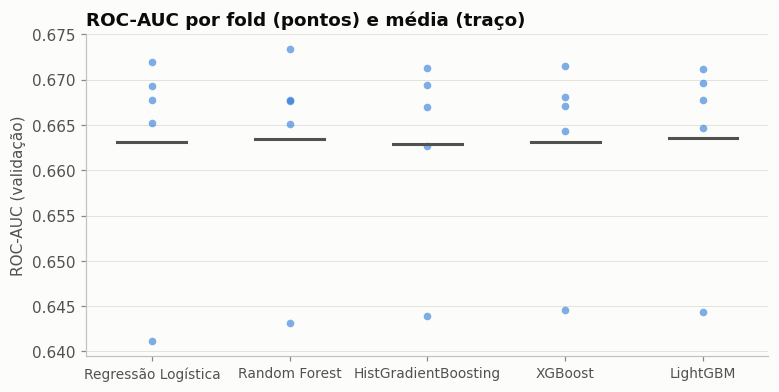

In [6]:
# ROC-AUC por fold – a diferença entre os algoritmos é maior que a variação entre folds?
auc_folds = pd.DataFrame({n: r["test_roc_auc"] for n, r in resultados_cv.items() if "Baseline" not in n})
fig, ax = plt.subplots(figsize=(8, 3.8))
for i, (nome, v) in enumerate(auc_folds.items()):
    ax.scatter(np.full(len(v), i), v, color=AZUL, s=25, alpha=0.6)
    ax.plot([i - 0.25, i + 0.25], [v.mean()] * 2, color=TEXTO_2, linewidth=2)
ax.set_xticks(range(auc_folds.shape[1]), auc_folds.columns, fontsize=9)
ax.set_ylabel("ROC-AUC (validação)"); ax.grid(axis="x", visible=False)
ax.set_title("ROC-AUC por fold (pontos) e média (traço)")
salvar(fig, "modelo_01_auc_por_fold")
plt.show()

**Leitura**
- **Todos os modelos superam o baseline** (ROC-AUC de 0,50) e ficam em torno de **0,66**.
- **A escolha do algoritmo quase não muda o resultado.** As diferenças entre eles (milésimos) são menores
  que a variação entre as partes da validação. Isso indica que o limite está na **informação disponível**,
  e não no algoritmo (ver seção 3).
- **Não há overfitting relevante:** a diferença entre treino e validação dos modelos de árvore fica em
  torno de 0,04, graças à regularização.

## 3. Vazamento de dados: o que acontece se ele não for tratado

Três experimentos com o mesmo LightGBM mostram quanto cada tipo de vazamento infla a métrica.

In [7]:
%%time
lgbm = modelos_candidatos()["LightGBM"]
experimentos = {}

# (a) Pipeline correta: validação agrupada por município (referência)
experimentos["Correto: CV agrupada por município"] = resultados_cv["LightGBM"]["test_roc_auc"].mean()

# (b) Validação aleatória: alunos do mesmo município em treino e validação
r = avaliar_cv(criar_pipeline(lgbm), X_tr, y_tr, None, KFold(5, shuffle=True, random_state=RANDOM_STATE))
experimentos["Vazamento (b): KFold aleatório"] = r["test_roc_auc"].mean()

# (c) Usar a taxa do MESMO ANO da rede do aluno (agregado que contém o próprio aluno)
redes24 = pd.read_parquet(ROOT / "data/processed/gold_municipio_redes.parquet").query("ano == 2024")
aux = df[["id_municipio", "rede_ensino"]].merge(redes24, on="id_municipio", how="left")
X_vaz = X_tr.copy()
X_vaz["taxa_rede_mesmo_ano"] = np.where(aux["rede_ensino"] == "Estadual", aux["taxa_alfabetizacao_estadual"],
                                        aux["taxa_alfabetizacao_municipal"])[idx_tr]
r = avaliar_cv(criar_pipeline(lgbm, NUMERICAS + ["taxa_rede_mesmo_ano"]), X_vaz, y_tr, g_tr, cv)
experimentos["Vazamento (c): taxa do mesmo ano"] = r["test_roc_auc"].mean()

# (d) Usar a proficiência (variável que define o rótulo)
prof = (pd.read_parquet(ROOT / "data/processed/gold_alunos.parquet")
        .query("ano == 2024").set_index("id_aluno")["proficiencia"])
X_prof = X_tr.copy()
X_prof["proficiencia"] = df["id_aluno"].map(prof).values[idx_tr]
r = avaliar_cv(criar_pipeline(lgbm, NUMERICAS + ["proficiencia"]), X_prof, y_tr, g_tr, cv)
experimentos["Vazamento (d): proficiência"] = r["test_roc_auc"].mean()

vaz = pd.Series(experimentos, name="ROC-AUC validação")
vaz.round(4).to_frame()

CPU times: total: 10min 41s
Wall time: 1min 11s


,ROC-AUC validação
Correto: CV agrupada por município,0.6635
Vazamento (b): KFold aleatório,0.6707
Vazamento (c): taxa do mesmo ano,0.6848
Vazamento (d): proficiência,1.0000


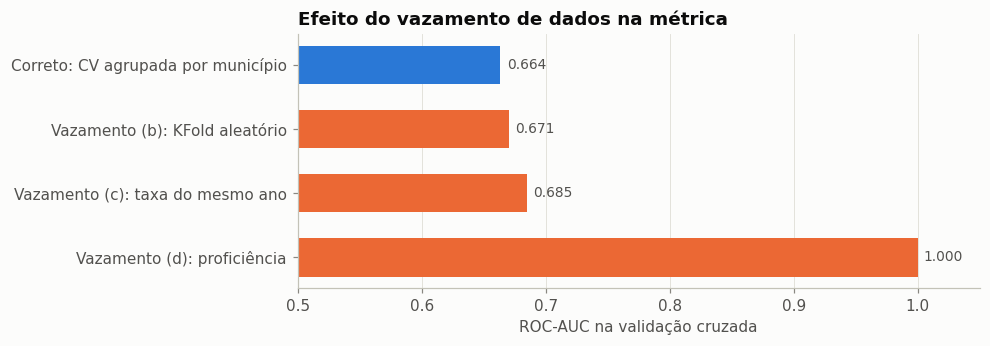

In [8]:
fig, ax = plt.subplots(figsize=(8, 3))
cores = [AZUL] + [LARANJA] * (len(vaz) - 1)
ax.barh(vaz.index[::-1], vaz.values[::-1], color=cores[::-1], height=0.6)
for i, v in enumerate(vaz.values[::-1]):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=9, color=TEXTO_2)
ax.set_xlim(0.5, 1.05); ax.grid(axis="y", visible=False)
ax.set_xlabel("ROC-AUC na validação cruzada")
ax.set_title("Efeito do vazamento de dados na métrica")
salvar(fig, "modelo_02_leakage")
plt.show()

**Leitura**
- **Proficiência: ROC-AUC de 1,00.** O modelo só reproduz o corte de 743 pontos. Não serve na prática,
  porque a proficiência só existe depois da prova. Por isso ela foi excluída, assim como `peso_aluno`.
- **Taxa do mesmo ano: 0,685.** A métrica sobe porque esse número já inclui o resultado do aluno e dos
  colegas. Ele serve como **teto de referência**: mesmo conhecendo o resultado final do município, a ROC-AUC
  fica perto de 0,69. O modelo legítimo (0,66) chega perto desse teto. O restante provavelmente depende de
  informações individuais (família, turma, frequência), que não existem na base.
- **Validação aleatória: 0,671.** Muda pouco aqui, mas a validação por município continua sendo a
  correta, porque mede o desempenho em **municípios novos**, que é o uso real.
- **Outras proteções:** o pré-processamento é ajustado dentro da validação, e os alunos que não fizeram a
  prova ficaram fora da base, porque o resultado deles não é conhecido.

## 4. Ablação: contribuição de cada grupo de variáveis

In [9]:
%%time
cenarios = {
    "Território": (TERRITORIO_NUM, ALUNO_CAT + TERRITORIO_CAT),
    "+ Socioeconômicas": (TERRITORIO_NUM + SOCIOECONOMICAS, ALUNO_CAT + TERRITORIO_CAT),
    "+ Histórico 2023": (TERRITORIO_NUM + SOCIOECONOMICAS + HISTORICO_EDUCACIONAL, ALUNO_CAT + TERRITORIO_CAT),
    "+ Metas (completo)": (NUMERICAS, CATEGORICAS),
    "Só histórico 2023 + rede": (HISTORICO_EDUCACIONAL, ALUNO_CAT),
}
ablacao = {}
for nome, (num, cat) in cenarios.items():
    r = avaliar_cv(criar_pipeline(modelos_candidatos()["LightGBM"], num, cat), X_tr[num + cat], y_tr, g_tr, cv)
    ablacao[nome] = (r["test_roc_auc"].mean(), r["test_roc_auc"].std())
ablacao = pd.DataFrame(ablacao, index=["roc_auc", "desvio"]).T
ablacao.round(4)

CPU times: total: 16min 40s
Wall time: 1min 47s


,roc_auc,desvio
Território,0.6484,0.0124
+ Socioeconômicas,0.6509,0.0127
+ Histórico 2023,0.6628,0.0097
+ Metas (completo),0.6635,0.0098
Só histórico 2023 + rede,0.6588,0.0084


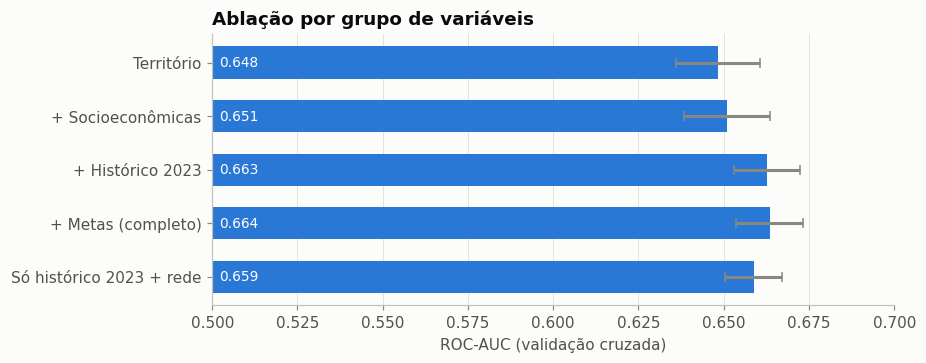

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(ablacao.index[::-1], ablacao["roc_auc"][::-1], xerr=ablacao["desvio"][::-1], color=AZUL, height=0.6,
        error_kw=dict(ecolor=CINZA, capsize=3))
for i, v in enumerate(ablacao["roc_auc"][::-1]):
    ax.text(0.502, i, f"{v:.3f}", va="center", fontsize=9, color="white")
ax.set_xlim(0.5, 0.7); ax.grid(axis="y", visible=False)
ax.set_xlabel("ROC-AUC (validação cruzada)")
ax.set_title("Ablação por grupo de variáveis")
salvar(fig, "modelo_03_ablacao")
plt.show()

**Leitura**
- **Só com território** (UF, região, porte e rede), o modelo chega a 0,648, perto do modelo completo
  (0,664). Isso reforça a hipótese H1 da análise exploratória.
- **As variáveis socioeconômicas acrescentam pouco** (+0,003) quando o território já está no modelo. A UF
  provavelmente já carrega boa parte desse contexto.
- **O histórico de 2023 é o grupo mais valioso** (hipótese H2): sozinho, com a rede, chega a 0,659.
- **As metas quase não acrescentam informação** (+0,001), provavelmente porque foram definidas a partir do
  resultado de 2023, que já está no modelo.

## 5. Otimização de hiperparâmetros

Busca aleatória (`RandomizedSearchCV`) com validação por município: 20 combinações para o **LightGBM** e
10 para a **Regressão Logística** (regularização `C`). No LightGBM, a busca prioriza os parâmetros que
**controlam overfitting**: mínimo de alunos por folha, número de folhas, subamostragem e regularização L1/L2.

In [11]:
%%time
lgbm_base = modelos_candidatos()["LightGBM"].set_params(n_jobs=1)
busca_lgbm = otimizar(criar_pipeline(lgbm_base), ESPACO_LGBM, X_tr, y_tr, g_tr, n_iter=20)
busca_log = otimizar(criar_pipeline(modelos_candidatos()["Regressão Logística"]), ESPACO_LOGISTICA,
                     X_tr, y_tr, g_tr, n_iter=10)
print(f"LightGBM  – melhor ROC-AUC CV: {busca_lgbm.best_score_:.4f}")
print(f"Logística – melhor ROC-AUC CV: {busca_log.best_score_:.4f} (C = {busca_log.best_params_['modelo__C']:.4f})")
tabela_busca(busca_lgbm).round(4)

LightGBM  – melhor ROC-AUC CV: 0.6641
Logística – melhor ROC-AUC CV: 0.6633 (C = 0.0315)
CPU times: total: 26.9 s
Wall time: 3min 40s


,colsample_bytree,learning_rate,min_child_samples,n_estimators,num_leaves,reg_alpha,reg_lambda,subsample,mean_test_score,std_test_score,mean_train_score,gap
9,0.8633,0.0158,521,212,14,0.0062,5.7820,0.9161,0.6641,0.0103,0.6833,0.0192
16,0.7886,0.0100,308,508,9,0.1104,1.0814,0.6888,0.6641,0.0112,0.6829,0.0188
3,0.5753,0.0232,239,712,6,2.7527,4.8440,0.7802,0.6640,0.0108,0.6911,0.0271
19,0.4198,0.0221,434,552,5,0.1330,1.2859,0.8212,0.6640,0.0108,0.6827,0.0187
11,0.6225,0.0466,148,696,4,0.0340,25.5299,0.9396,0.6636,0.0107,0.6907,0.0271
7,0.8364,0.0212,511,401,24,0.0359,0.4701,0.9315,0.6634,0.0098,0.7087,0.0453
18,0.9775,0.0179,435,536,20,0.0117,26.2539,0.7644,0.6629,0.0107,0.7056,0.0427
14,0.9657,0.0397,292,235,31,5.2335,10.0418,0.8534,0.6628,0.0102,0.7142,0.0514
17,0.4719,0.0218,423,757,27,0.6487,0.7957,0.9887,0.6628,0.0090,0.7228,0.0600
12,0.8330,0.0172,447,542,18,0.0513,0.1156,0.6432,0.6627,0.0100,0.7041,0.0415


In [12]:
# Hiperparâmetros escolhidos para o LightGBM.
pd.Series({k.replace("modelo__", ""): v for k, v in busca_lgbm.best_params_.items()}).to_frame("valor")

,valor
colsample_bytree,0.863347
learning_rate,0.015802
min_child_samples,521.000000
n_estimators,212.000000
num_leaves,14.000000
reg_alpha,0.006243
reg_lambda,5.782029
subsample,0.916070


### Escolha do algoritmo

Os dois modelos otimizados empatam na prática: ROC-AUC de 0,664 contra 0,663 na validação, e de 0,635
contra 0,633 no teste. O **LightGBM** foi escolhido como modelo final porque:
1. **capta interações sem precisar especificá-las**, como a relação com o IDHM que muda entre regiões
   (hipótese H3). Nesta base, porém, o ganho de desempenho foi marginal;
2. **permite calcular o SHAP de forma exata** (TreeExplainer), base da interpretabilidade do notebook 05.

A **Regressão Logística** fica como modelo de referência: é mais simples de explicar e serve para conferir
se as conclusões se mantêm.

## 6. Avaliação final no teste (municípios nunca vistos)

### Escolha do limiar de decisão
O objetivo é **identificar alunos em risco de não se alfabetizar**. O limiar foi escolhido com as previsões
da validação cruzada (nunca com o teste), buscando o melhor F1 para a classe "não alfabetizado".

In [13]:
%%time
modelo_final = busca_lgbm.best_estimator_
oof = cross_val_predict(modelo_final, X_tr, y_tr, groups=g_tr, cv=cv, method="predict_proba")[:, 1]
limiar = limiar_otimo_f1(y_tr, oof, alvo_classe=0)
print(f"Limiar escolhido (máx. F1 da classe 'não alfabetizado' no treino): {limiar:.3f}")

proba_te = modelo_final.predict_proba(X_te)[:, 1]
proba_te_log = busca_log.best_estimator_.predict_proba(X_te)[:, 1]
# Precisão, Recall, F1 e PR-AUC calculados para a classe de interesse: NÃO alfabetizado.
foco = dict(classe_foco=0, nome_classe="não alfabetizado")
res_teste = pd.DataFrame({
    "LightGBM (limiar 0,50)": metricas(y_te, proba_te, 0.5, **foco),
    f"LightGBM (limiar {limiar:.2f})".replace(".", ","): metricas(y_te, proba_te, limiar, **foco),
    "Logística (limiar 0,50)": metricas(y_te, proba_te_log, 0.5, **foco),
}).T
res_teste.to_csv(REPORTS_DIR / "metricas_teste_modelo_alunos.csv")
res_teste.round(4)

Limiar escolhido (máx. F1 da classe 'não alfabetizado' no treino): 0.699
CPU times: total: 12.6 s
Wall time: 12.7 s


,ROC-AUC,PR-AUC (não alfabetizado),Log loss,Brier,Acurácia balanceada,Precisão (não alfabetizado),Recall (não alfabetizado),F1 (não alfabetizado),Limiar
"LightGBM (limiar 0,50)",0.6348,0.5088,0.6401,0.2256,0.5607,0.5552,0.2568,0.3511,0.500
"LightGBM (limiar 0,70)",0.6348,0.5088,0.6401,0.2256,0.5699,0.4376,0.9054,0.5901,0.699
"Logística (limiar 0,50)",0.6330,0.5060,0.6404,0.2258,0.5731,0.5494,0.3176,0.4025,0.500


In [14]:
# Recall/precisão da classe de interesse (NÃO alfabetizado) com o limiar escolhido.
from sklearn.metrics import classification_report
pred_te = (proba_te >= limiar).astype(int)
print(f"Alunos sinalizados como risco: {(pred_te == 0).mean():.1%} | "
      f"proporção real de não alfabetizados: {(y_te == 0).mean():.1%}")
print(classification_report(y_te, pred_te, target_names=["Não alfabetizado", "Alfabetizado"], digits=3))

Alunos sinalizados como risco: 82.1% | proporção real de não alfabetizados: 39.7%
                  precision    recall  f1-score   support

Não alfabetizado      0.438     0.905     0.590      3996
    Alfabetizado      0.790     0.234     0.361      6072

        accuracy                          0.501     10068
       macro avg      0.614     0.570     0.476     10068
    weighted avg      0.650     0.501     0.452     10068



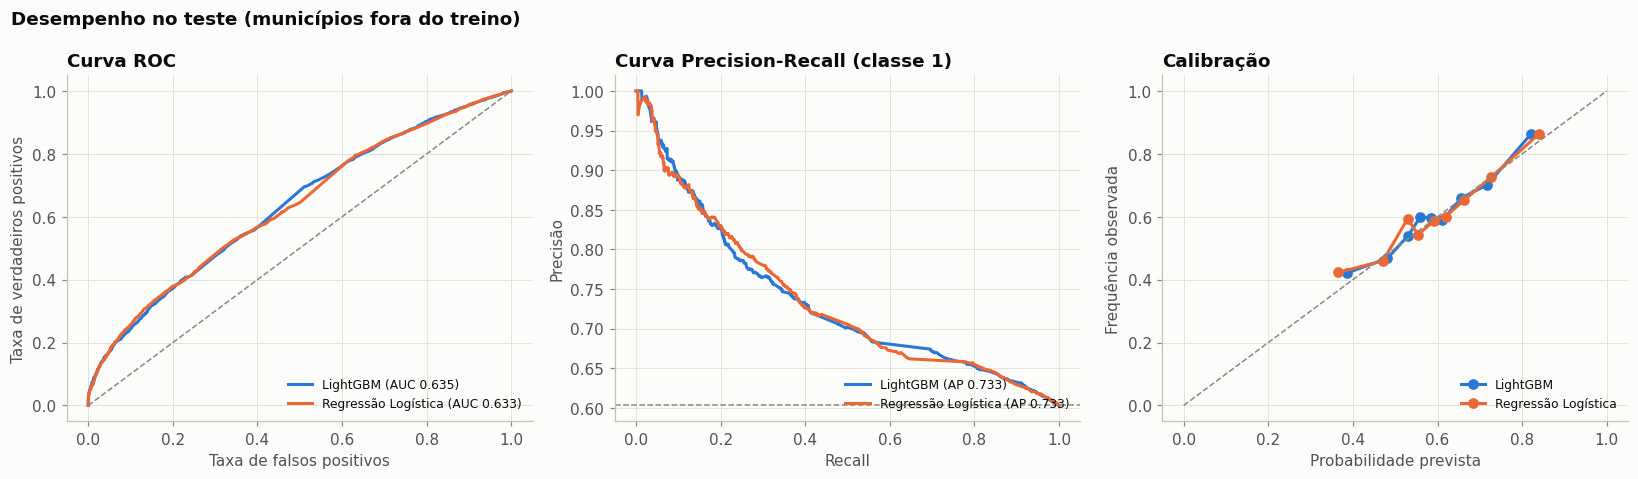

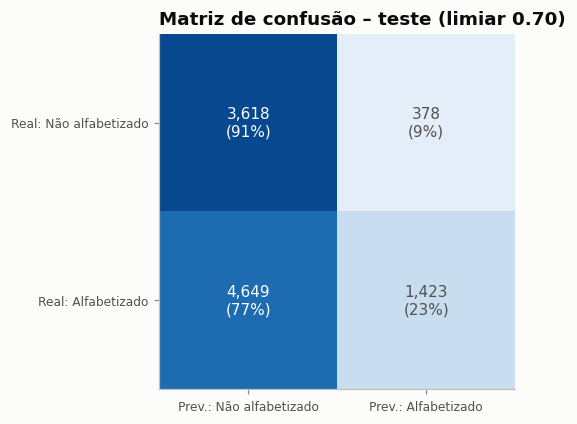

In [15]:
fig = grafico_avaliacao(y_te, {"LightGBM": proba_te, "Regressão Logística": proba_te_log},
                        "Desempenho no teste (municípios fora do treino)")
salvar(fig, "modelo_04_roc_pr_calibracao")
plt.show()
fig = grafico_matriz_confusao(y_te, pred_te, titulo=f"Matriz de confusão – teste (limiar {limiar:.2f})")
salvar(fig, "modelo_05_matriz_confusao")
plt.show()

In [16]:
# Intervalo de confiança da AUC no teste: bootstrap reamostrando MUNICÍPIOS (não alunos).
ic = bootstrap_metrica(y_te, proba_te, roc_auc_score, n=300, grupos=g_te)
print(f"ROC-AUC teste = {roc_auc_score(y_te, proba_te):.4f} | IC 95% (bootstrap por município): [{ic[0]:.4f}; {ic[2]:.4f}]")
print(f"ROC-AUC médio na validação cruzada: {busca_lgbm.best_score_:.4f}")

ROC-AUC teste = 0.6348 | IC 95% (bootstrap por município): [0.6078; 0.6623]
ROC-AUC médio na validação cruzada: 0.6641


### Utilidade prática: priorização
A pergunta da gestão é: **se eu priorizar os alunos de maior risco previsto (na prática, as redes de maior
risco), quantos dos não alfabetizados eu alcanço?**

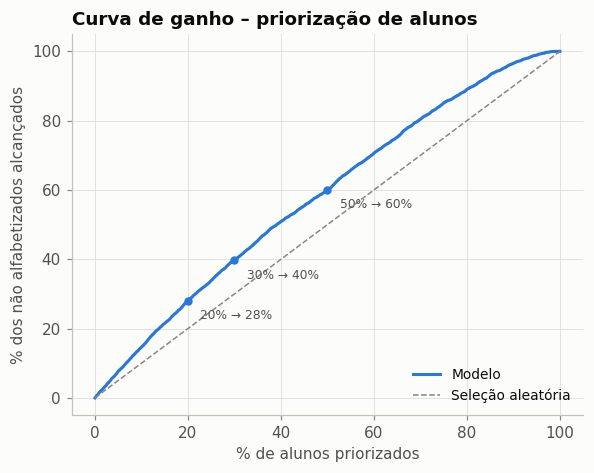

,% dos não alfabetizados alcançados
10% priorizados,14.6
20% priorizados,28.1
30% priorizados,39.7
40% priorizados,50.9
50% priorizados,60.1


In [17]:
# Curva de ganho: % de não alfabetizados capturados ao priorizar X% dos alunos (menor probabilidade primeiro).
ordem = np.argsort(proba_te)
nao_alf = (1 - y_te.values)[ordem]
captura = np.cumsum(nao_alf) / nao_alf.sum()
frac = np.arange(1, len(ordem) + 1) / len(ordem)
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(frac * 100, captura * 100, color=AZUL, label="Modelo")
ax.plot([0, 100], [0, 100], color=CINZA, linestyle="--", linewidth=1, label="Seleção aleatória")
for p in [0.2, 0.3, 0.5]:
    c = captura[int(p * len(captura)) - 1]
    ax.scatter(p * 100, c * 100, color=AZUL, s=30, zorder=3)
    ax.annotate(f"{p:.0%} → {c:.0%}", (p * 100, c * 100), xytext=(8, -12), textcoords="offset points", fontsize=8, color=TEXTO_2)
ax.set_xlabel("% de alunos priorizados"); ax.set_ylabel("% dos não alfabetizados alcançados")
ax.set_title("Curva de ganho – priorização de alunos"); ax.legend(loc="lower right")
salvar(fig, "modelo_06_curva_ganho")
plt.show()
ganho = pd.Series({f"{p:.0%} priorizados": captura[int(p * len(captura)) - 1] for p in [0.1, 0.2, 0.3, 0.4, 0.5]})
(ganho * 100).round(1).to_frame("% dos não alfabetizados alcançados")

### Generalização por região

In [18]:
# Desempenho do modelo no teste, por região.
te = df.iloc[idx_te].assign(proba=proba_te)
por_regiao = te.groupby("regiao").apply(lambda d: pd.Series({
    "alunos": len(d), "municípios": d["id_municipio"].nunique(),
    "% alfabetizados real": d["alfabetizado"].mean(), "% previsto (média)": d["proba"].mean(),
    "ROC-AUC": roc_auc_score(d["alfabetizado"], d["proba"])}), include_groups=False)
por_regiao.round(3)

,alunos,municípios,% alfabetizados real,% previsto (média),ROC-AUC
regiao,,,,,
Centro-Oeste,1388.0,78.0,0.637,0.611,0.607
Nordeste,2181.0,323.0,0.586,0.569,0.693
Norte,1126.0,93.0,0.514,0.510,0.587
Sudeste,3977.0,268.0,0.627,0.606,0.599
Sul,1396.0,187.0,0.600,0.610,0.647


**Leitura**
- **No teste, a ROC-AUC foi de 0,635** (IC 95%: 0,61 a 0,66), um pouco abaixo da validação (0,664). A
  diferença é compatível com a variação entre conjuntos de municípios vista na seção 7. Não há sinal de
  overfitting: a diferença entre treino e validação do modelo otimizado é de cerca de 0,02.
- **O modelo mantém poder de separação em todas as regiões**, com ROC-AUC entre 0,59 (Norte) e 0,69
  (Nordeste). As probabilidades médias previstas ficaram a até 3 pontos das taxas reais, o que indica uma
  calibração razoável por região.
- **O limiar de 0,70 sinaliza quase todos os alunos.** Ele alcança 90% dos não alfabetizados, mas marca
  82% de todos os alunos como risco, e só 44% dos sinalizados de fato não se alfabetizaram (a proporção
  geral é de 40%). Na prática, esse limiar não ajuda a focalizar.
- **Para priorizar, a ordenação por risco é mais útil que o limiar.** Priorizar os 30% de maior risco
  alcança 40% dos não alfabetizados, contra 30% ao acaso. O ganho é real, mas moderado, coerente com a
  ROC-AUC. O corte pode ser definido pela capacidade de atendimento de cada rede.

## 7. Replicabilidade

In [19]:
%%time
# A conclusão depende da semente? Repete o hold-out com outras 4 divisões de municípios.
estab = []
for seed in [1, 7, 21, 99]:
    i_tr, i_te = dividir_por_grupo(X, y, grupos, seed=seed)
    m = criar_pipeline(modelos_candidatos()["LightGBM"].set_params(**{k.replace("modelo__", ""): v for k, v in busca_lgbm.best_params_.items()}))
    m.fit(X.iloc[i_tr], y.iloc[i_tr])
    estab.append({"semente": seed, "ROC-AUC teste": roc_auc_score(y.iloc[i_te], m.predict_proba(X.iloc[i_te])[:, 1])})
estab = pd.DataFrame(estab)
print(f"ROC-AUC em 4 divisões diferentes: {estab['ROC-AUC teste'].mean():.4f} ± {estab['ROC-AUC teste'].std():.4f}")
estab.round(4)

ROC-AUC em 4 divisões diferentes: 0.6547 ± 0.0149
CPU times: total: 1min 22s
Wall time: 9.56 s


,semente,ROC-AUC teste
0,1,0.6578
1,7,0.6717
2,21,0.6354
3,99,0.6538


**Leitura**
- **A ROC-AUC variou de 0,635 a 0,672** entre divisões diferentes de municípios (média de 0,655). A divisão
  principal (semente 42) foi a mais difícil, então o resultado reportado tende a ser **conservador**.
- **A variação vem de quais municípios caem no teste.** Por isso, o resultado é apresentado com intervalo,
  e não como um número único.
- **Ressalva:** essas divisões reaproveitam os hiperparâmetros escolhidos na divisão principal, então podem
  estar levemente otimistas.
- **A replicabilidade se apoia em:** semente única (`RANDOM_STATE = 42`) nas divisões, na validação e nos
  modelos; pipeline versionada em `src/`; dados versionados em `data/`; dependências em `requirements.txt`.

In [20]:
# Treina o modelo final com TODO o conjunto de treino (já feito pelo refit) e salva.
salvar_modelo(modelo_final, "modelo_alunos_lgbm", {
    "algoritmo": "LightGBM", "hiperparametros": busca_lgbm.best_params_, "limiar_risco": limiar,
    "roc_auc_cv": busca_lgbm.best_score_, "roc_auc_teste": roc_auc_score(y_te, proba_te),
    "variaveis_numericas": NUMERICAS, "variaveis_categoricas": CATEGORICAS,
    "treino_alunos": len(X_tr), "teste_alunos": len(X_te),
})
# Guarda os índices do hold-out para os notebooks de interpretabilidade.
pd.Series(idx_te).to_csv(REPORTS_DIR / "indices_teste_alunos.csv", index=False)
print("Modelo salvo em models/modelo_alunos_lgbm.joblib")

Modelo salvo em models/modelo_alunos_lgbm.joblib


## Resumo

| Item | Resultado |
|---|---|
| Algoritmo final | LightGBM otimizado, dentro de uma pipeline scikit-learn |
| Validação | Cruzada por município + teste com 20% dos municípios |
| ROC-AUC (validação cruzada) | 0,664 ± 0,010 |
| ROC-AUC (teste) | 0,635 (IC 95%: 0,61 a 0,66); 0,655 ± 0,015 em outras 4 divisões |
| Teto de referência (com vazamento) | ≈ 0,69, usando o resultado do próprio ano |
| Priorização | 30% de maior risco → 40% dos não alfabetizados (30% ao acaso) |
| Limiar de 0,70 | Alcança 90% dos não alfabetizados, mas sinaliza 82% dos alunos |
| Vazamento tratado | Proficiência, peso, presença, agregados do mesmo ano, pré-processamento na validação, divisão por município |

**O desempenho moderado reflete o limite da informação disponível antes da prova**, e não uma falha da
modelagem: nem o teste com vazamento passa de 0,69. Como as variáveis são do município e da rede, o modelo
serve para **priorizar redes e municípios**, com o corte definido pela capacidade de atendimento.